In [5]:
!pip install fairlearn


In [6]:
# Import libraries
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate, false_positive_rate,
    demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference)
from fairlearn.postprocessing import ThresholdOptimizer

In [7]:
# Load dataset
df = pd.read_csv('adult.csv')
print(df.shape)
df.head()

(32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [8]:
# Clean: remove rows containing '?'
df = df.replace('?', np.nan).dropna().reset_index(drop=True)
print(df.shape)

(30162, 15)


In [9]:
# Target (1 = >50K), sensitive feature (sex), features without sex
y = (df['income'].str.strip() == '>50K').astype(int)
A = df['sex']
X = df.drop(columns=['income', 'sex'])
print(y.mean(), A.value_counts().to_dict())

0.24892248524633645 {'Male': 20380, 'Female': 9782}


In [10]:
# 70:30 stratified split, random_state=42
X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    X, y, A, test_size=0.30, random_state=42, stratify=y)

In [11]:
# One-hot encode categoricals, scale numerics
cat = X.select_dtypes('object').columns.tolist()
num = X.select_dtypes(exclude='object').columns.tolist()
pre = ColumnTransformer([('num', StandardScaler(), num),
                         ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])

In [12]:
# Task 1: train Logistic Regression (no sex)
model = Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Baseline Accuracy:', round(accuracy_score(y_test, y_pred), 2))

Baseline Accuracy: 0.85


In [13]:
# Task 2: MetricFrame per sex
mf = MetricFrame(metrics={'accuracy': accuracy_score, 'selection_rate': selection_rate,
                          'TPR': true_positive_rate, 'FPR': false_positive_rate},
                 y_true=y_test, y_pred=y_pred, sensitive_features=A_test)
print(mf.by_group.round(2))

        accuracy  selection_rate   TPR   FPR
sex                                         
Female      0.92            0.09  0.53  0.03
Male        0.82            0.26  0.62  0.09


In [14]:
# Task 3: baseline fairness metrics
def fair(y_pred):
    return (demographic_parity_difference(y_test, y_pred, sensitive_features=A_test),
            demographic_parity_ratio(y_test, y_pred, sensitive_features=A_test),
            equalized_odds_difference(y_test, y_pred, sensitive_features=A_test))
dpd, dpr, eod = fair(y_pred)
print(f'DP difference: {dpd:.2f}\nDP ratio (DI): {dpr:.2f}  ->', 'BIAS' if dpr < 0.8 else 'OK', f'\nEO difference: {eod:.2f}')

DP difference: 0.17
DP ratio (DI): 0.34  -> BIAS 
EO difference: 0.08


In [15]:
# Task 4: ThresholdOptimizer - demographic parity
to_dp = ThresholdOptimizer(estimator=model, constraints='demographic_parity',
                           objective='accuracy_score', prefit=True, predict_method='predict_proba')
to_dp.fit(X_train, y_train, sensitive_features=A_train)
pred_dp = to_dp.predict(X_test, sensitive_features=A_test, random_state=42)
print('Accuracy:', round(accuracy_score(y_test, pred_dp), 2), '| DP diff, DP ratio, EO diff:', np.round(fair(pred_dp), 2))

Accuracy: 0.83 | DP diff, DP ratio, EO diff: [0.   0.99 0.3 ]


In [16]:
# Task 5: ThresholdOptimizer - equalized odds
to_eo = ThresholdOptimizer(estimator=model, constraints='equalized_odds',
                           objective='accuracy_score', prefit=True, predict_method='predict_proba')
to_eo.fit(X_train, y_train, sensitive_features=A_train)
pred_eo = to_eo.predict(X_test, sensitive_features=A_test, random_state=42)
print('Accuracy:', round(accuracy_score(y_test, pred_eo), 2), '| DP diff, DP ratio, EO diff:', np.round(fair(pred_eo), 2))

Accuracy: 0.83 | DP diff, DP ratio, EO diff: [0.09 0.61 0.02]


In [17]:
# Task 6: comparison table
rows = []
for name, p in [('Baseline', y_pred), ('TO: demographic_par.', pred_dp), ('TO: equalized_odds', pred_eo)]:
    sr = MetricFrame(metrics=selection_rate, y_true=y_test, y_pred=p, sensitive_features=A_test).by_group
    d, r, e = fair(p)
    rows.append([name, accuracy_score(y_test, p), sr['Male'], sr['Female'], d, r, e])
table = pd.DataFrame(rows, columns=['MODEL', 'ACC', 'SEL_M', 'SEL_F', 'DP_DIFF', 'DP_RATIO', 'EO_DIFF']).round(2)
print(table.to_string(index=False))
table.to_csv('comparison_table.csv', index=False)

               MODEL  ACC  SEL_M  SEL_F  DP_DIFF  DP_RATIO  EO_DIFF
            Baseline 0.85   0.26   0.09     0.17      0.34     0.08
TO: demographic_par. 0.83   0.18   0.17     0.00      0.99     0.30
  TO: equalized_odds 0.83   0.23   0.14     0.09      0.61     0.02


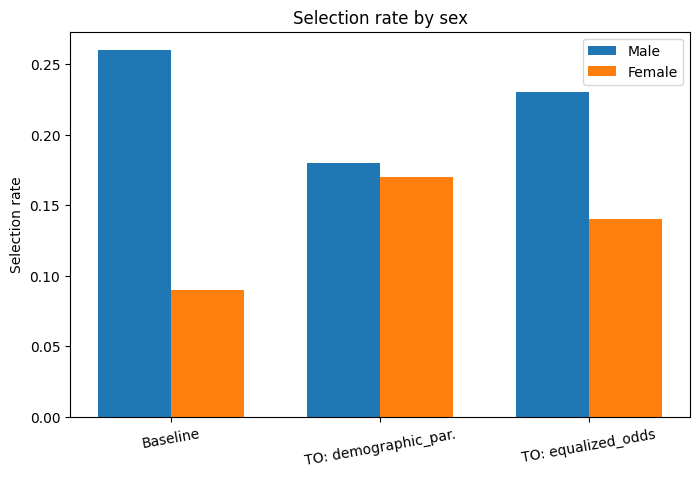

In [18]:
# Task 6: selection rate plot by sex
x = np.arange(len(table)); w = 0.35
plt.figure(figsize=(8, 5))
plt.bar(x - w/2, table['SEL_M'], w, label='Male')
plt.bar(x + w/2, table['SEL_F'], w, label='Female')
plt.xticks(x, table['MODEL'], rotation=10); plt.ylabel('Selection rate')
plt.title('Selection rate by sex'); plt.legend()
plt.savefig('selection_rate_by_sex.png', dpi=150, bbox_inches='tight'); plt.show()